# Final project - data visualization not using arctic region data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

## Data
Load data and merge into one dataframe using Lat and Lon columns to align the different dataframes.

In [3]:
LAT_LON = ["Lat", "Lon"]

# LPJ-GUESS 
lpj_df = pd.read_csv("data/LPJ-GUESS_output_BERN1.csv")
lpj_df = lpj_df.rename(columns={col: col + f"_lpj" for col in lpj_df.columns if not col in LAT_LON})

# Grid information
grid_df = pd.read_csv("data/gridlist_pan_gfed_ISO3_UN_ecoregion.txt", sep=' ')
grid_df = grid_df.rename(columns={col: col + f"_grid" for col in grid_df.columns if not col in LAT_LON})

# Soil texture
soil_df = pd.read_csv("data/soilmap.dat", sep="\t")
soil_df = soil_df.dropna().rename(columns={"lon": "Lon", "lat": "Lat"})
soil_df = soil_df.rename(columns={col: col + f"_soil" for col in soil_df.columns if not col in LAT_LON})

# Load all climate statistics datafiles and put in one dictionary
stats_files = {
    "tswrf": "Tswrfdaymean1961_1990_stats.csv",
    "pre": "Predaymean1961_1990_stats.csv",
    "tmp": "Tmpdaymean1961_1990_stats.csv",
    "tmax": "Tmaxdaymean1961_1990_stats.csv",
    "tmin": "Tmindaymean1961_1990_stats.csv"}

stats_df = {}
for name, path in stats_files.items():
    df = pd.read_csv("data/" + path)
    df = df.rename(columns={col: col + f"_{name}" for col in df.columns if not col in LAT_LON})
    stats_df[name] = df

# Merge all dataframes on Lat and Lon
merged_df = lpj_df.merge(grid_df, on=LAT_LON, how="inner").merge(soil_df, on=LAT_LON, how="inner") # soil and grid info
for name, df in stats_df.items(): # climate dfs
    merged_df = merged_df.merge(df, on=LAT_LON, how="inner")

Two functions used to remove columns in the merged df for downstream analysis:

In [4]:
def drop_ground_truth(df):
    """Drops Lat, Lon, and all columns ending with '_lpj' or '_grid'."""
    return df.loc[:, [col for col in df.columns if not col.endswith(("_lpj", "_grid")) and col not in ["Lat", "Lon"]]]

def drop_columns(df, str_in_columns_to_drop, keep_columns=None):
    """Drops columns containing a specified string, except specified columns."""
    keep_columns = keep_columns or []
    return df.loc[:, [col for col in df.columns if str_in_columns_to_drop not in col or col in keep_columns]]
    

In [5]:
# Drop median columns
merged_df = drop_columns(merged_df, "Median")

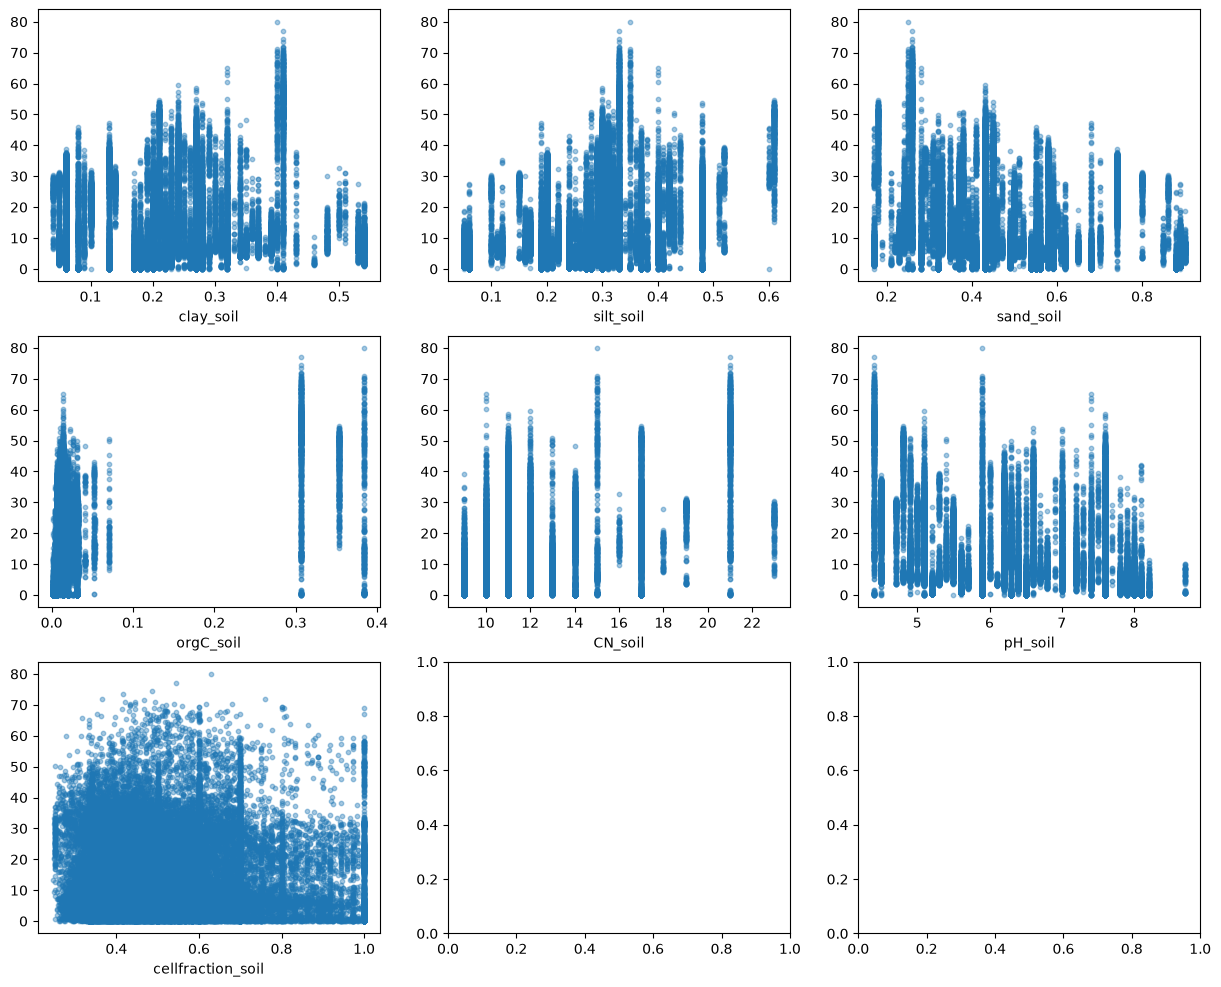

In [6]:
import matplotlib.pyplot as plt
import math

soil_features = [col for col in merged_df.columns if col.endswith("_soil")]
ncols = 3
nrows = math.ceil(len(soil_features) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for ax, feature in zip(axes, soil_features):
    data = merged_df[[feature, "SoilC_lpj"]]
    ax.scatter(data[feature], data["SoilC_lpj"], alpha=0.4, s=10)
    ax.set_xlabel(feature)

Don't use CN? Also don't know what cellfraction is. Don't use this either

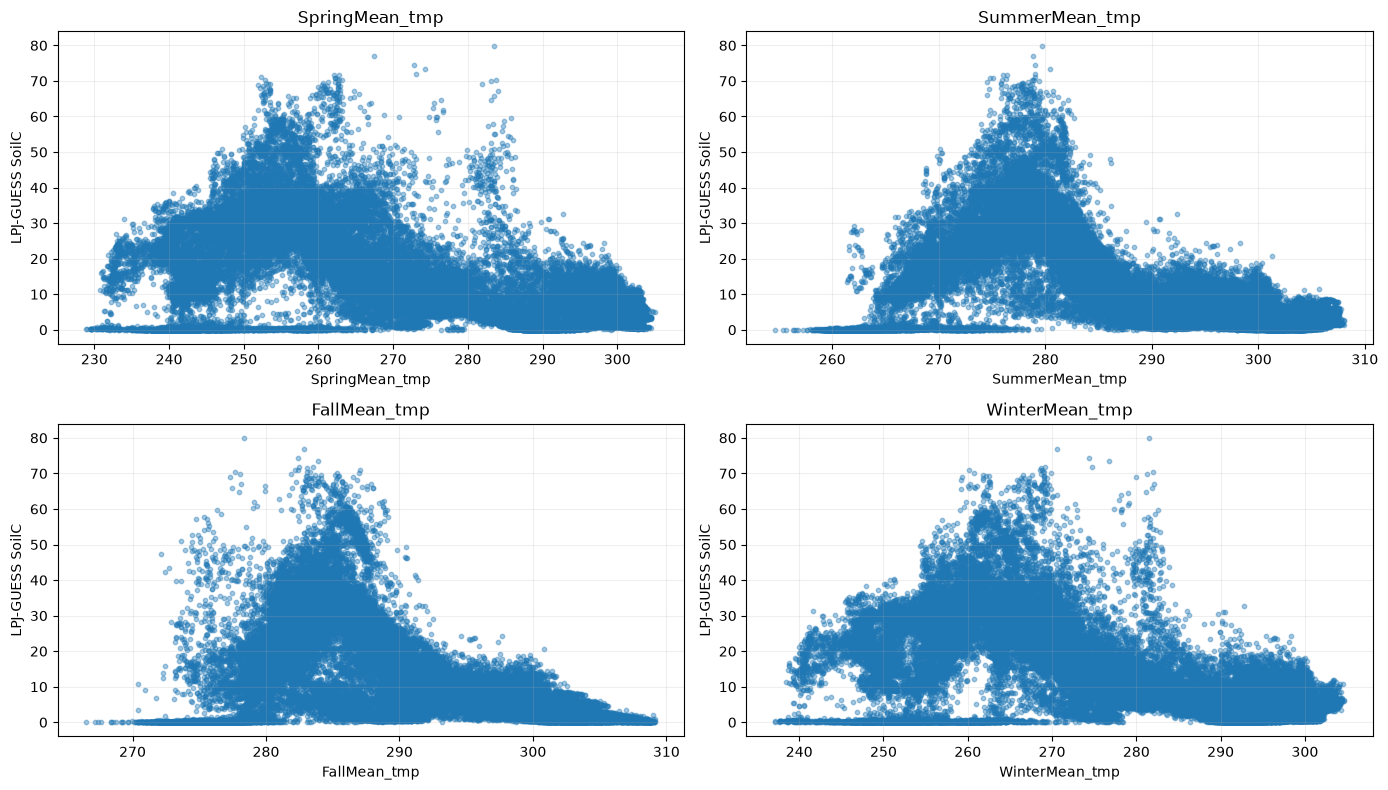

In [7]:
temp_cols = [col for col in merged_df.columns if "Mean_tmp" in col]
fig, axes = plt.subplots(2, (len(temp_cols) + 1) // 2, figsize=(14, 8))
for ax, col in zip(axes.flat, temp_cols):
    ax.scatter(merged_df[col], merged_df["SoilC_lpj"], alpha=0.4, s=10)
    ax.set(xlabel=col, ylabel="LPJ-GUESS SoilC", title=col)
    ax.grid(alpha=0.2)
for ax in axes.flat[len(temp_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## Neural Network

In [8]:
# Divide the data into x and y
# x: imput features that will help predict y
# y: soil carbon

# copy the stuff from the convolutional neural network from the first exercise
# 3-4 layers
# per parameter i want 10 datapoints (1/N)^4 then i can have 8-10 input features ish. if then i have 6 points per parameter. better with less imput features. 10 features, 4 layers = 10 000 parameters (weights)
# dodnt have enough datapoints to make a transformer
# Presentation is 10 minutes